In [1]:
%load_ext autoreload
%autoreload 2
import random
import numpy as np
import torch

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

# Usage
set_seed(42)

In [ ]:
# from lcb import LCB, LCBModel
# import os
# from nets import ValueEstimate, LogUBaselineNet, train_val_estimate, load_val_estimate
# from collection import Collector
# run_id = "20260110_153817_039025"
# run_dir = os.path.join("toy_data_runs", run_id)
# alpha = 0.2

# value_estimator, _, index_set, _ = load_val_estimate(run_id, alpha, device="mps")
# collector = Collector(None, None)
# core, _, expr = collector.load_collected(run_dir)
# in_dim = value_estimator.in_dim
# lcb = LCB(
#         in_dim, 
#         value_estimator,
#         core,
#         delta = 0.1,
#         fix_lambda=False,
#         symmetric= False,
#         lambda_value=10,
#         lam_min=1,
#         lam_max=20.0,
#         erm_error=0.0,
#     )

# core.S = 5000

# model = LCBModel(core, lcb)
# model.num_train_steps_per_t = 400
# model.num_baseline_epochs_per_step = 2
# X = model.train() # X = (S, d)
# lcb.save(run_dir, args.run_id, alpha)

LCB Model has S =  5000
Training LCB at t=18...
Training LCB at t=17...
Training LCB at t=16...
Training LCB at t=15...
Training LCB at t=14...
Training LCB at t=13...
Training LCB at t=12...
Training LCB at t=11...
Training LCB at t=10...
Training LCB at t=9...
Training LCB at t=8...
Training LCB at t=7...
Training LCB at t=6...
Training LCB at t=5...
Training LCB at t=4...
Training LCB at t=3...
Training LCB at t=2...
Training LCB at t=1...


In [105]:
model.num_steps/(5000*20)

22.7952

In [70]:
X.shape

(20, 10000, 2)

In [ ]:
%load_ext autoreload
%autoreload 2
from lcb_no_forget import LCB, LCBModel
import os
from nets import ValueEstimate, LogUBaselineNet, train_val_estimate, load_val_estimate
from collection import Collector
run_id = "20260122_202321_157606"
run_dir = os.path.join("toy_data_runs", run_id)
alpha = 0.2

set_seed(42)

value_estimator, states, index_set, _ = load_val_estimate(run_id, alpha, device="mps")
collector = Collector(None, None)
core, states, expr = collector.load_collected(run_dir)


core.S = 7000
print("states shape:", states.shape)
in_dim = value_estimator.in_dim

# Train LCB ################
    

lcb = LCB(
    2, 
    value_estimator,
    core,
    delta = 0.3,
    fix_lambda=False,
    symmetric= False,
    lambda_value=10,
    lam_min=1,
    lam_max=20.0,
    erm_error=0.0,
)

model = LCBModel(core, lcb)
model.num_train_steps_per_t = 400
model.num_baseline_epochs_per_step = 1
X = model.train()







print("num proposals = ", model.num_steps)


# print("Trained lambdas per timestep:", lambdas)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
states shape: (20, 70000, 2)
LCB Model has S =  7000
Training LCB at t=18...
Training LCB at t=17...
Training LCB at t=16...
Training LCB at t=15...
Training LCB at t=14...
Training LCB at t=13...
Training LCB at t=12...
Training LCB at t=11...
Training LCB at t=10...
Training LCB at t=9...
Training LCB at t=8...
Training LCB at t=7...
Training LCB at t=6...
Training LCB at t=5...
Training LCB at t=4...
Training LCB at t=3...
Training LCB at t=2...
Training LCB at t=1...
num proposals =  847225


In [ ]:

lcb_delta_0p1 = LCB(
    2, 
    value_estimator,
    core,
    delta = 0.1,
    fix_lambda=False,
    symmetric= False,
    lambda_value=10,
    lam_min=1,
    lam_max=20.0,
    erm_error=0.0,
    baseline_lr = 1e-3
)

model_delta_0p1 = LCBModel(core, lcb)
model_delta_0p1.num_train_steps_per_t = 400
model_delta_0p1.num_baseline_epochs_per_step = 1
X = model_delta_0p1.train()







print("num proposals = ", model_delta_0p1.num_steps)


# print("Trained lambdas per timestep:", lambdas)


LCB Model has S =  7000
Training LCB at t=18...
Training LCB at t=17...
Training LCB at t=16...
Training LCB at t=15...
Training LCB at t=14...
Training LCB at t=13...
Training LCB at t=12...
Training LCB at t=11...
Training LCB at t=10...
Training LCB at t=9...
Training LCB at t=8...
Training LCB at t=7...
Training LCB at t=6...
Training LCB at t=5...
Training LCB at t=4...
Training LCB at t=3...
Training LCB at t=2...
Training LCB at t=1...
num proposals =  813353


In [6]:
model_delta_0p1.num_steps/(7000*20)

5.809664285714286

In [8]:

lcb_delta_0p1 = LCB(
    2, 
    value_estimator,
    core,
    delta = 0.3,
    fix_lambda=False,
    symmetric= False,
    lambda_value=10,
    lam_min=1,
    lam_max=20.0,
    erm_error=0.0,
    baseline_lr = 1e-3
)

model_delta_0p3 = LCBModel(core, lcb)
model_delta_0p3.num_train_steps_per_t = 400
model_delta_0p3.num_baseline_epochs_per_step = 1
X = model_delta_0p3.train()







print("Effective N = ", model_delta_0p3.num_steps/(7000*20))


# print("Trained lambdas per timestep:", lambdas)


LCB Model has S =  7000
Training LCB at t=18...
Training LCB at t=17...
Training LCB at t=16...
Training LCB at t=15...
Training LCB at t=14...
Training LCB at t=13...
Training LCB at t=12...
Training LCB at t=11...
Training LCB at t=10...
Training LCB at t=9...
Training LCB at t=8...
Training LCB at t=7...
Training LCB at t=6...
Training LCB at t=5...
Training LCB at t=4...
Training LCB at t=3...
Training LCB at t=2...
Training LCB at t=1...
Effective N =  6.2543


In [ ]:
lcb_2 = lcb
lcb_2.load_lcb(run_dir, run_id, value_estimator, core, alpha, "_ASYM")

LCB(
  (value_estimator): ValueEstimate(
    (net): Sequential(
      (0): Linear(in_features=3, out_features=128, bias=True)
      (1): ReLU(inplace=True)
      (2): Linear(in_features=128, out_features=500, bias=True)
      (3): ReLU(inplace=True)
      (4): Linear(in_features=500, out_features=500, bias=True)
      (5): ReLU(inplace=True)
      (6): Linear(in_features=500, out_features=1, bias=True)
    )
    (criterion): MSELoss()
  )
  (nets): ModuleList(
    (0-19): 20 x SingleStepNet(
      (net): Sequential(
        (0): Linear(in_features=2, out_features=64, bias=True)
        (1): ReLU(inplace=True)
        (2): Linear(in_features=64, out_features=64, bias=True)
        (3): ReLU(inplace=True)
        (4): Linear(in_features=64, out_features=1, bias=True)
      )
    )
  )
)

In [30]:
model.lcb.lambdas

[19.999611864684418,
 19.999611864684418,
 15.267948403915511,
 19.999611864684418,
 19.999611864684418,
 16.996362978702493,
 13.728451478376055,
 9.14768492980786,
 19.997579561787575,
 6.878824088578543,
 10.181947752423795,
 19.999611864684418,
 15.514616801185053,
 7.681307648475281,
 8.294986815483231,
 10.029498298960759,
 9.447263198674557,
 19.999611864684418,
 None,
 None]

In [17]:
sampler_2 = LCBModel(core, lcb_2)
sampler_2.infer()

LCB Model has S =  7000
vt shape: (7000, 5)
btp1 shape: (7000,)
tau_t shape: (7000, 5)
acc shape: (7000, 5)
acc =  [[0.22085679 0.21692586 0.2253041  0.22709034 0.22375707]
 [0.2141404  0.22340022 0.21077782 0.21338245 0.2222298 ]
 [0.23126458 0.23258913 0.2278799  0.23381443 0.23335133]
 ...
 [0.2568668  0.25090924 0.251235   0.24851646 0.25579947]
 [0.23989218 0.24743325 0.23857251 0.2504123  0.24207667]
 [0.24083933 0.24170703 0.24635139 0.2402441  0.23479745]]
vt shape: (1789, 5)
btp1 shape: (1789,)
tau_t shape: (1789, 5)
acc shape: (1789, 5)
acc =  [[0.2247123  0.23097578 0.23110259 0.2304625  0.22146896]
 [0.2456463  0.24327669 0.27070883 0.24852362 0.24805549]
 [0.17518723 0.17572415 0.17390908 0.1736791  0.17291921]
 ...
 [0.20989037 0.2163403  0.22345887 0.21802159 0.21446843]
 [0.2449102  0.20094122 0.21048257 0.21063873 0.20883948]
 [0.25172055 0.2573307  0.25598055 0.25239173 0.25397116]]
vt shape: (455, 5)
btp1 shape: (455,)
tau_t shape: (455, 5)
acc shape: (455, 5)
acc = 

array([[-9.48951768,  1.6921336 ],
       [ 6.42028492, -2.63395686],
       [-7.62629306, -0.74467004],
       ...,
       [-7.77883617,  0.17781801],
       [-8.05455196,  1.56291357],
       [ 5.40478129, -0.59940581]])

In [21]:
sampler_2.num_steps

840363

In [28]:
model.num_steps/(7000*20)

6.051607142857143

In [11]:
from animate_2d import animate_val_predictions
alpha_str = str(alpha).replace(".", "p")
animate_val_predictions(states, index_set, lcb, outfile=f"{run_dir}/lcb_{alpha_str}_ASYM.gif")


Predictions shape: (20, 2500)
Value prediction range: -6.493989 2.9758923


'toy_data_runs/20260122_202321_157606/lcb_0p2_ASYM.gif'

In [35]:
# model.num_steps = 0
X_infer = model.infer()

In [36]:
model.num_steps/(7000*20)

6.045028571428571

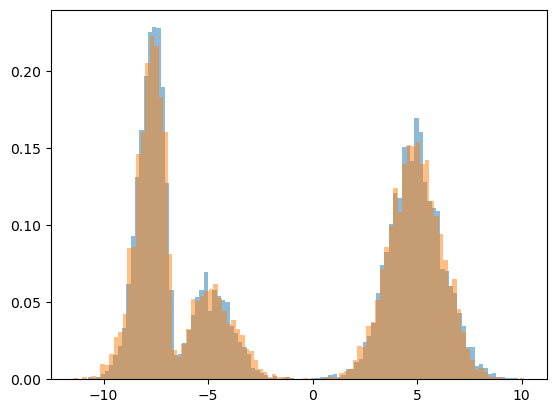

In [37]:
import matplotlib.pyplot as plt
# plt.scatter(X[ :, 0], X[ :, 1], c='blue', alpha=0.5)

# plt.hist(X[:, 0], bins = 100, density=True, alpha=0.5)
plt.hist(states[0, :, 0], bins = 100, density=True, alpha=0.5)
plt.hist(X_infer[:, 0], bins = 100, density=True, alpha=0.5)
plt.show()

[[14.257255  13.640412  13.729818  14.32004   13.62331  ]
 [13.9795885 14.506212  14.981055  14.737645  14.5435295]
 [14.926777  14.598251  14.208072  14.919718  14.920337 ]
 ...
 [12.837166  12.791619  12.633174  12.041496  12.651246 ]
 [13.721585  13.210387  13.137274  13.366464  13.178734 ]
 [16.719597  16.980867  16.620745  17.090881  16.841034 ]]
[[11.449672  11.735404  11.706207  11.279544  11.530458 ]
 [13.79248   13.380292  13.225996  13.393314  13.596569 ]
 [ 7.1014433  6.9940968  6.7883463  7.082722   6.867881 ]
 ...
 [ 7.5062294  7.6636477  7.665855   7.595967   7.493859 ]
 [ 6.865962   6.9028893  6.6865134  6.8834834  6.4983525]
 [14.978501  14.600796  14.729106  14.818263  15.033233 ]]
[[2.9419525 2.909138  3.3252132 3.202899  3.2784579]
 [7.6583104 9.631904  7.5666885 7.545665  7.734306 ]
 [3.9900122 3.3834677 3.5804222 3.4494522 3.5843306]
 ...
 [8.961699  9.009674  8.957538  8.79144   9.074317 ]
 [2.8407047 2.911783  2.973469  2.970561  2.756596 ]
 [3.2920067 3.231275  

(array([  3.,   1.,   2.,   5.,   7.,   5.,  17.,  18.,  27.,  23.,  13.,
         11.,   5.,  10.,  26.,  21.,  24.,  29.,  41.,  29.,  37.,  38.,
         40.,  34.,  30.,  25.,  31.,  22.,  28.,  15.,  12.,  11.,   4.,
         11.,   5.,   5.,   1.,   5.,   4.,   1.,   1.,   0.,   0.,   1.,
          2.,   0.,   0.,   0.,   1.,   0.,   1.,   1.,   2.,   0.,   5.,
          3.,   3.,  14.,  14.,  17.,  12.,  28.,  44.,  60.,  66.,  87.,
         81.,  89., 119., 150., 162., 204., 198., 225., 223., 248., 260.,
        254., 221., 188., 217., 206., 164., 133.,  98., 104., 108.,  80.,
         57.,  41.,  34.,  24.,  20.,  21.,  16.,   5.,   4.,   0.,   4.,
          4.]),
 array([-8.58558388, -8.40795292, -8.23032196, -8.05269101, -7.87506005,
        -7.69742909, -7.51979813, -7.34216718, -7.16453622, -6.98690526,
        -6.8092743 , -6.63164335, -6.45401239, -6.27638143, -6.09875047,
        -5.92111952, -5.74348856, -5.5658576 , -5.38822664, -5.21059569,
        -5.03296473, -4.85

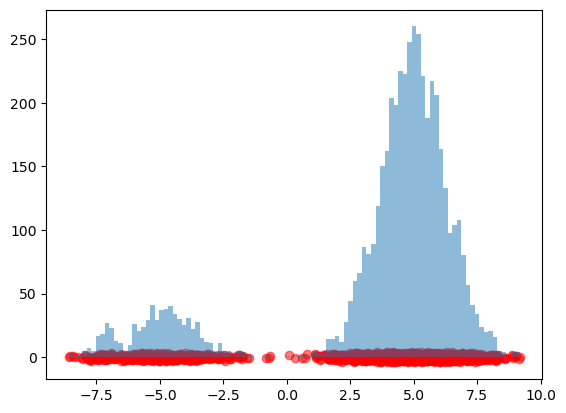

In [16]:
X_infer = model.infer()
plt.scatter(X_infer[:, 0], X_infer[:, 1], c='red', alpha=0.5)
plt.hist(X_infer[:, 0], bins=100, alpha=0.5, label='X_infer dim 0')

In [31]:
import numpy as np

class RejectionSampling:
    """
    Simple rejection sampling policy analogous to LCBModel.lcb_step, but with
    acceptance probability:   p_accept = exp(v_t(x_t) - B)

    where v_t is provided in *log-space* by value_estimator.predict_under_log(...),
    and B is a user-chosen constant (typically >= max log v so p<=1 mostly).
    """
    def __init__(self, core, value_estimator, B: float, N: int = 5):
        self.core = core
        self.core.reset()
        self.value_estimator = value_estimator
        self.index_set = self.core.model_config["index_set"]
        self.B = float(B)
        self.N = int(N)

        self.S = self.core.S
        self.num_steps = 0  # total proposals used (like LCBModel.num_steps)

    def rs_step(self):
        """
        Perform one reverse-time step (t+1 -> t) using rejection sampling.
        Mirrors LCBModel.lcb_step structure.

        Returns:
            accepted_states: (S, d) np.ndarray
            num_proposals:   length-S list[int] proposals consumed per chain
        """
        tp1 = self.core.t  # current time index is "t+1" in their convention
        if tp1 < 0:
            raise ValueError(f"rs_step called with core.t={tp1}; expected t>=1 (so we can go to t-1).")

        Xtp1 = self.core.X  # (S, d)
        S = Xtp1.shape[0]

        # proposals per active chain per loop-iteration
        self.core.N = self.N

        active = list(range(S))
        accepted_states = [None] * S
        num_proposals = [0] * S

        # Loop until every chain accepts a proposal
        while active:
            # Propose candidates for currently-active indices.
            # Expected shape: (N, len(active), d)
            Xt = self.core.propose_external(Xtp1[active], tp1, N=self.core.N)

            # log v_t for each proposed state at time t = tp1-1
            # expected shape: (N, len(active))
            logvt = self.value_estimator.predict_under_log(Xt, self.index_set[tp1 - 1])

            acc = np.exp(logvt - self.B)
            acc = np.clip(acc, 0.0, 1.0)

            u = np.random.rand(*acc.shape)

            # Ensure acc is shaped (A, N): rows = active chains, cols = proposals
            # A = len(active), N = self.core.N
            A = len(active)
            N = self.core.N
            if acc.shape == (N, A):
                acc = acc.T
                u = u.T
            elif acc.shape != (A, N):
                raise ValueError(f"Unexpected acc shape {acc.shape}; expected {(A, N)} or {(N, A)}")

            new_active = []
            for j, orig_idx in enumerate(active):
                ok = np.where(acc[j, :] > u[j, :])[0]
                if ok.size:
                    first = int(ok[0])
                    # Xt could be (N, A, d) or (A, N, d) depending on Core; handle both.
                    if Xt.shape[:2] == (N, A):
                        accepted_states[orig_idx] = Xt[first, j]
                    elif Xt.shape[:2] == (A, N):
                        accepted_states[orig_idx] = Xt[j, first]
                    else:
                        raise ValueError(f"Unexpected Xt shape {Xt.shape}; expected {(N, A, 'd')} or {(A, N, 'd')}")
                    num_proposals[orig_idx] += first + 1
                else:
                    new_active.append(orig_idx)
                    num_proposals[orig_idx] += N

            active = new_active


        accepted_states = np.stack(accepted_states, axis=0)
        self.core.commit(accepted_states)
        self.num_steps += int(sum(num_proposals))
        return accepted_states, num_proposals

    def set_S(self, S: int):
        self.core.S = int(S)
        self.S = int(S)
        self.core.reset()

    def calc_samples(self):
        """
        Roll out samples using rejection sampling, returning an array of shape (T+1, S, d),
        matching LCBModel.calc_samples().
        """
        self.core.reset()
        self.num_steps = 0

        # initial noisy state at time T
        init_props = self.core.propose()
        if init_props.ndim == 3:
            x_init = init_props[:, 0, :]
        else:
            x_init = init_props
        self.core.commit(x_init)

        T_plus_1 = self.core.T + 1
        d = x_init.shape[-1]
        states = np.empty((T_plus_1, self.S, d))
        states[self.core.t + 1] = x_init  # time index T

        while self.core.t >= 0:
            states_t, _ = self.rs_step()
            states[self.core.t] = states_t

        return states


# ---------------------------------------------------------------------
# Example usage (mirrors how you use LCBModel)
# ---------------------------------------------------------------------
# rs = RejectionSampling(core=core, value_estimator=value_estimator, B=YOUR_B, N=5)
# rs.core.S = 5000
# rs.set_S(5000)
# states = rs.calc_samples()
# print("num proposals:", rs.num_steps)


rs = RejectionSampling(core=core, value_estimator=value_estimator, B=1/alpha)
# rs.core.S = 5000
rs.set_S(7000)
states = rs.calc_samples()
print("proposal per timestep ratio:", rs.num_steps/(7000*20))


proposal per timestep ratio: 63.83225


In [76]:
X_lcb_bo2_candidates = X.reshape(20, 5000, 2, 2)[0]
X_lcb_bo2_candidates.shape


(5000, 2, 2)

In [99]:
S = 100
X_lcb_bo2_candidates = X.reshape(20, S, 2, -1)[0]
rewards = np.where(X_lcb_bo2_candidates[...,0] < -7, 1, 0)
print(rewards.shape)
best_indices = np.argmax(rewards, axis=1)
print(best_indices.shape)
X_lcb_bo2 = X_lcb_bo2_candidates[np.arange(S), best_indices, :]
print(X_lcb_bo2.shape)


(100, 2)
(100,)
(100, 100)


In [1]:
import matplotlib.pyplot as plt
plt.hist(states[0, :, 0], bins=50, density=True, alpha=0.5, label="RS t=0")
plt.hist(X[:, 0], bins=100, density=True, alpha=0.5, label="RS t=0")
# plt.hist(X_lcb_bo2[:, 0], bins=50, density=True, alpha=0.5, label="RS t=0")

NameError: name 'states' is not defined

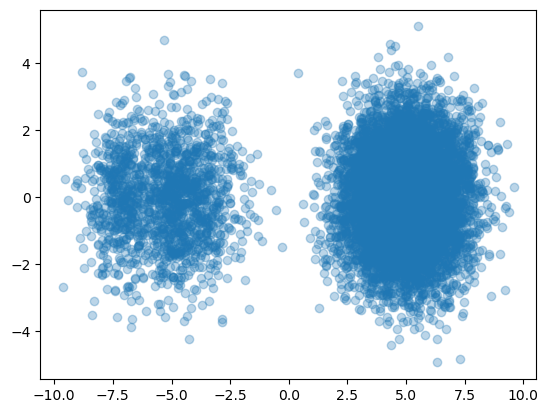

In [12]:
plt.scatter(X[0, :, 0], X[0, :, 1], alpha=0.3)

In [10]:
X.shape

(20, 5000, 2)